# Sparse real-pressure acoustic equivalent-source imaging

## 1. Problem


Reconstruct a **complex spatial equivalent monopole field**, not mechanical surface velocity, from108 real measured Fourier-pressure samples. The released pressure was individually amplitude-equalized and phase-shifted for four loudspeakers before summation. Its units are U, not absolute Pa; equivalent-source strengths have units U m³/(Pa s). No actual source-strength truth was measured.

The outgoing free-field model under exp(+i omega t) is G[m,j]=i omega rho exp(-ik r)/(4 pi r), with omega=2 pi1150, rho=1.2 kg/m³ and c=343 m/s. Two parallel planes are25mm apart; their inclusive grids span825 by600mm. There are2000 point-strength unknowns, no pixel-area multiplier and no fitted phase/gain.

The active review runs the original code's published **classical baselines** locally: SVD Tikhonov LN, first-order TV and the second-order derivative variant named TGV upstream. The latter penalizes the sum of the pixelwise complex-vector norms of (Dxx q,Dyy q); it is not auxiliary-field TGV or a scalar Laplacian penalty. The neural variational network is outside this selected-method scope and is not shown as reproduced. Original captures are identified comparisons, never fresh calculations or ground truth.

## 2. Data

These are existing, author-processed **real acoustic measurements**, not simulated observations. Separate loudspeaker impulse responses were Fourier transformed, each speaker's maximum pressure amplitude was equalized, its maximum-pressure phase shifted to zero, and the resulting fields summed. Only this composed field is supplied; the independent individual-speaker signals are unavailable. U denotes the retained author numerical pressure scale, not calibrated pascals.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| pressure | (1,9,12) | complex64 | Composed pressure in U; axes batch,y,x; real+i imaginary under exp(+i omega t). |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Frequency | 1150 | Hz | Single Fourier frequency; omega=2 pi frequency. |
| Sound speed | 343 | m/s | Uniform free-field medium. |
| Air density | 1.2 | kg/m³ | Factor in pressure-to-volume-velocity propagation. |
| Measurement plane height | 0.025 | m | Receiver z relative to source z=0. |
| Rectangle width | 0.825 | m | Both grids span x=0 to this inclusive endpoint. |
| Rectangle height | 0.600 | m | Both grids span y=0 to this inclusive endpoint. |
| Receiver grid | 9 rows, 12 columns | samples | Uniform inclusive y,x grids; row-major flattening. |
| Source grid | 40 rows, 50 columns | samples | Uniform inclusive y,x grids; row-major flattening. |
| Receiver spacing | 0.075 | m | Both x and y directions. |
| Source spacing x | 0.825/49 | m | Inclusive endpoints. |
| Source spacing y | 0.600/39 | m | Inclusive endpoints. |
| Coordinate axes | x columns, y rows, z toward receivers | convention | Right-handed spatial model. |
| Temporal convention | exp(+i omega t) | convention | Outgoing Green function exp(-ikr)/(4 pi r). |
| Boundary | free field, finite source rectangle | convention | No reflections or periodic extension; regularization may impose edge assumptions. |
| Noise | unknown | U | No independently calibrated noise variance is supplied. |

## 3. Physics

For receiver $m$ and source-grid point $j$ separated by $r_{mj}$ metres, the frequency-domain free-field operator is

$$
p_m=\sum_jG_{mj}q_j+\eta_m,\qquad G_{mj}=\frac{\mathrm i\omega\rho}{4\pi r_{mj}}e^{-\mathrm ikr_{mj}}.
$$

Here $\omega=2\pi(1150)$ s$^{-1}$, $k=\omega/343$ m$^{-1}$ and $\rho=1.2$ kg/m^3 under $e^{+\mathrm i\omega t}$. $p$ is the author's processed complex pressure in units U, and $q$ is equivalent point strength in U m^3/(Pa s). There is no source-pixel area factor. The 108 measured pressures constrain 2000 complex coefficients across a parallel plane 25 mm away, so spatial priors materially affect the inferred field.

## 4. Method

### Explicit inverse and execution

Minimize ||Gq-p||² + lambda sum sqrt(|Dxⁿq|²+|Dyⁿq|²), with n=1 or2. Differences use grid indices and right/bottom zero padding; their explicit Hermitian adjoint retains these finite boundaries. lambda=smax 10^(-SNR/20) ||p||/sqrt(2000), with SNR35dB for the derivative methods. This SNR is a regularization label, not a known instrument-noise variance. LN uses30dB and a quadratic source penalty.

Starting from zero, the20000 Condat–Vu steps use qnew=q-tau 2Gᴴ(Gq-p)-tau D*u and unew=proj_lambda(u+sigma D(2qnew-q)). tau=.5/smax²; sigma=(1/tau-smax²)/eps, with eps the original spectral-norm estimate from D*D(I100). Dual projection acts on each complex two-vector. Relaxation is1; additional fused sparsity is0. The following cell actually executes all three bound reconstructions and additional30/40dB sensitivity runs. A600s per-cell timeout allows the measured CPU runtime.

## 5. Results

All three full-data classical methods and the labeled regularization variants are computed locally. Their common scales compare model-conditioned equivalent sources; original reference discrepancy and measured-pressure residual answer separate questions.


In [1]:
%matplotlib inline
from pathlib import Path
import os,sys,json,time
task=Path.cwd()
if not (task/'src').is_dir(): task=task.parent
if not (task/'src').is_dir(): raise RuntimeError('Execute from the task or its notebooks directory')
sys.path.insert(0,str(task))
import numpy as np,torch,matplotlib.pyplot as plt
torch.set_num_threads(1)
from src.visualization import review
figure_dir=Path(os.environ.get('IMAGING_FIGURE_DIR',str(task/'output'/'review_figures')))
print('Active full reconstruction; CPU one thread; NumPy',np.__version__,'torch',torch.__version__)


Active full reconstruction; CPU one thread; NumPy 2.4.6 torch 2.9.1+cu128


In [2]:
start=time.perf_counter()
figures,measurements=review(task,figure_dir)
print('Total active review seconds:',time.perf_counter()-start)
print(json.dumps(measurements,indent=2))


Total active review seconds: 103.74494950000371
{
  "LN": {
    "seconds": 0.02485789999627741,
    "relative_complex_l2_original": 0.0,
    "observation_relative_l2": 0.21543346345424652,
    "lambda": 5626457600.0
  },
  "TV": {
    "seconds": 19.851014599997143,
    "relative_complex_l2_original": 0.0,
    "observation_relative_l2": 0.04258211329579353,
    "lambda": 3163989504.0
  },
  "TGV": {
    "seconds": 23.58847909999895,
    "relative_complex_l2_original": 0.0,
    "observation_relative_l2": 0.030362624675035477,
    "lambda": 3163989504.0
  },
  "judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "relative_complex_l2": 0.0,
      "magnitude_cosine": 1.0,
      "observation_relative_l2": 0.03036261152047294
    },
    "thresholds": {
      "relative_complex_l2": {
        "comparison": "<=",
        "boundary": 2e-05
      },
      "magnitude_cosine": {
        "comparison": ">=",
        "boundary": 0.999999
      },
      "observation_relative_l2": 

### Figure 1

Real processed pressure magnitude/phase and complex components; each receiver is shown at its actual pixel-center coordinate.


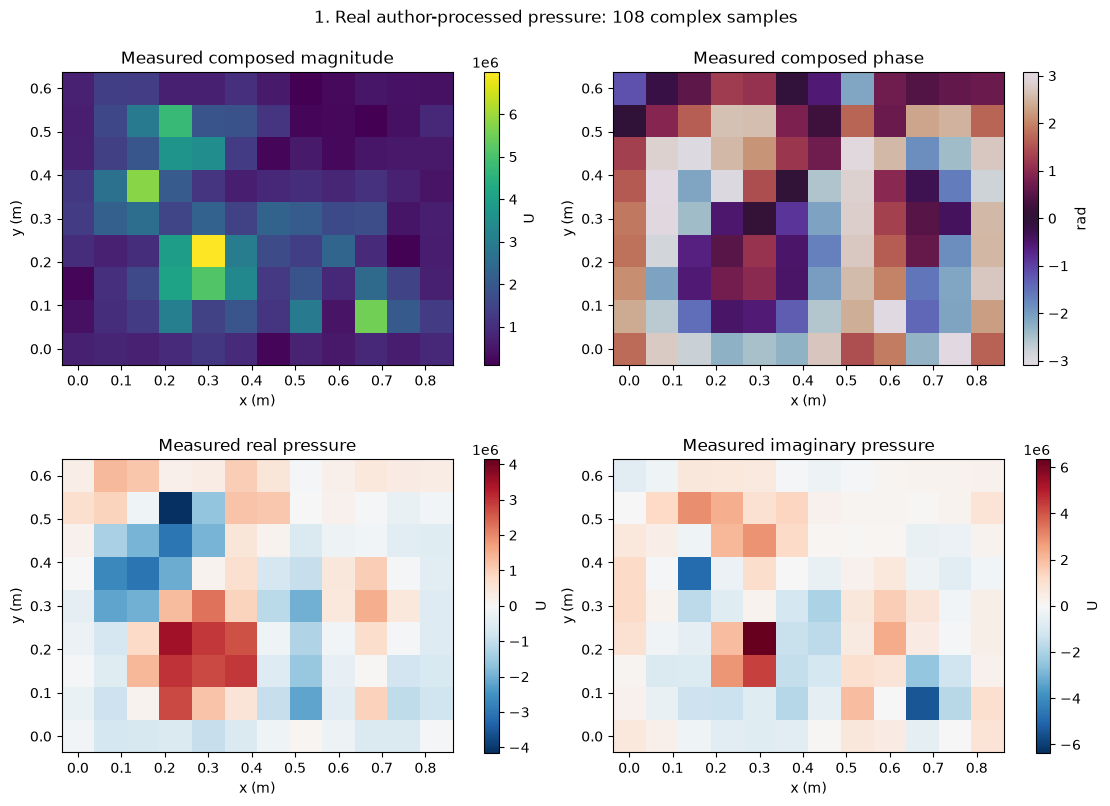

In [3]:
display(figures[0])
plt.close(figures[0])

### Figure 2

Original and fresh second-order estimates; numerical discrepancy is displayed separately. There is no independently measured q truth.


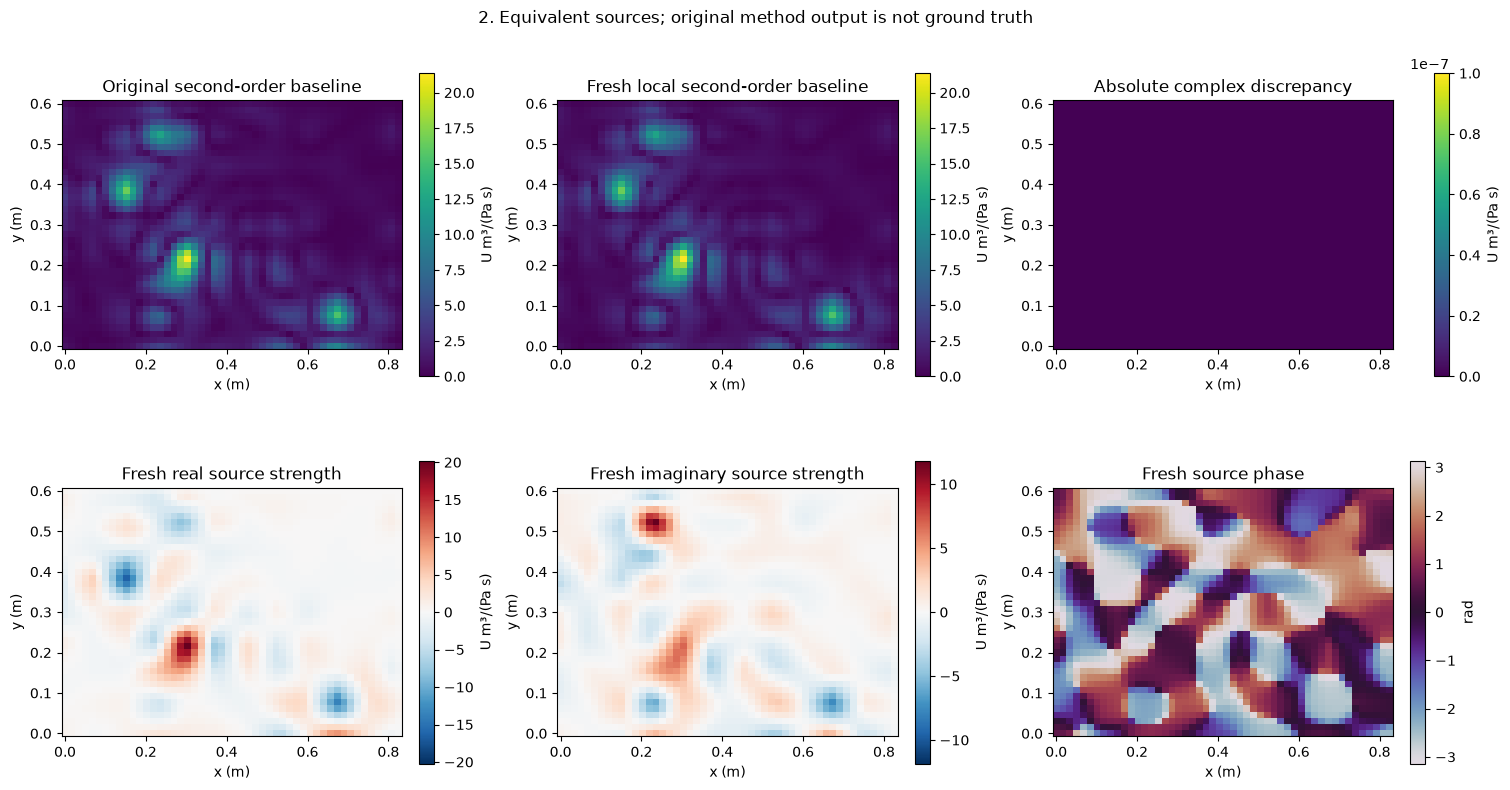

In [4]:
display(figures[1])
plt.close(figures[1])

### Figure 3

All three active baselines on the same observations with shared source/residual scales. A smaller residual alone does not establish source accuracy.


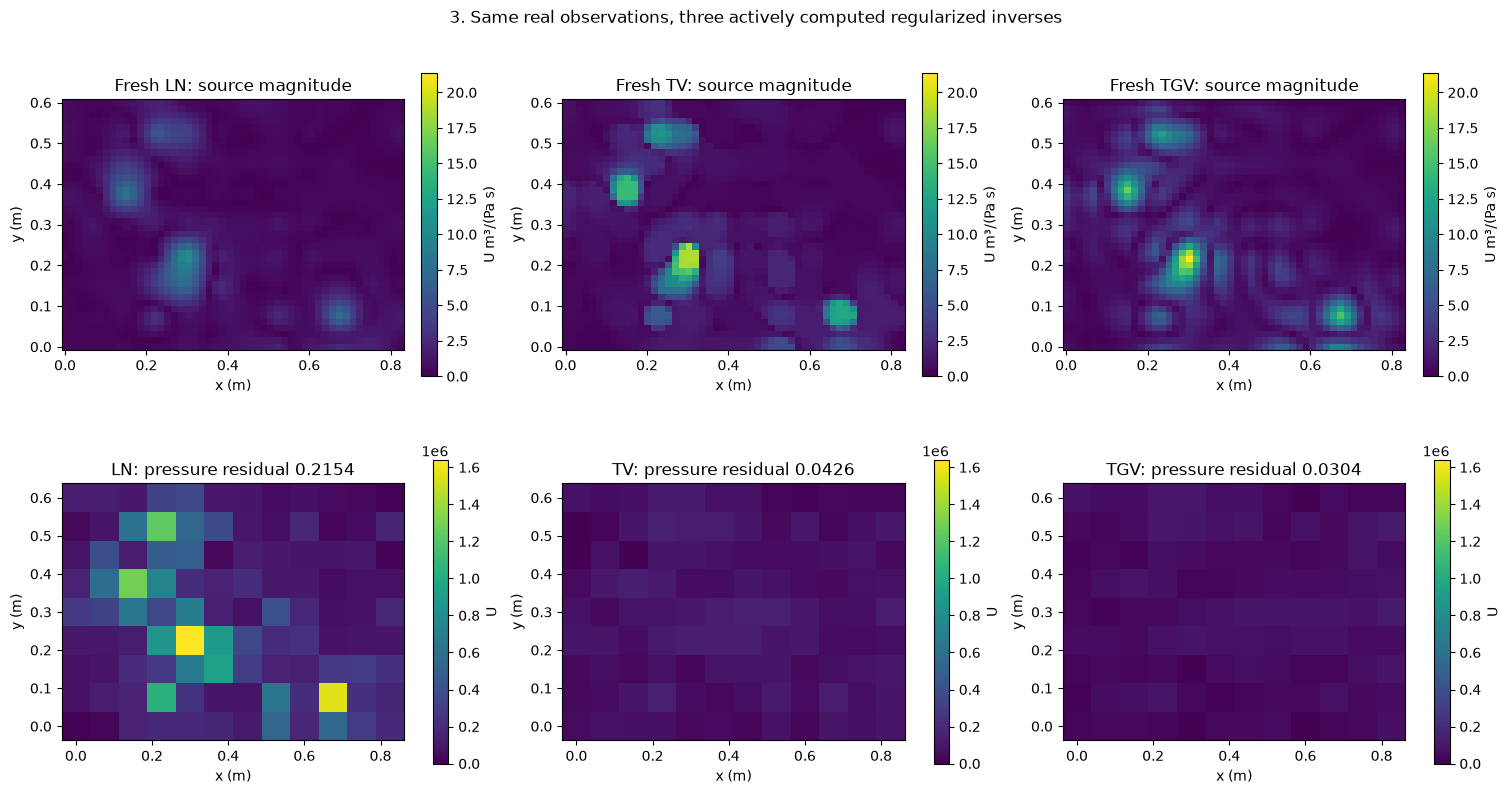

In [5]:
display(figures[2])
plt.close(figures[2])

### Figure 4

Fresh pressure reprojection, both complex components and all108 receiver samples; no fitted complex gain.


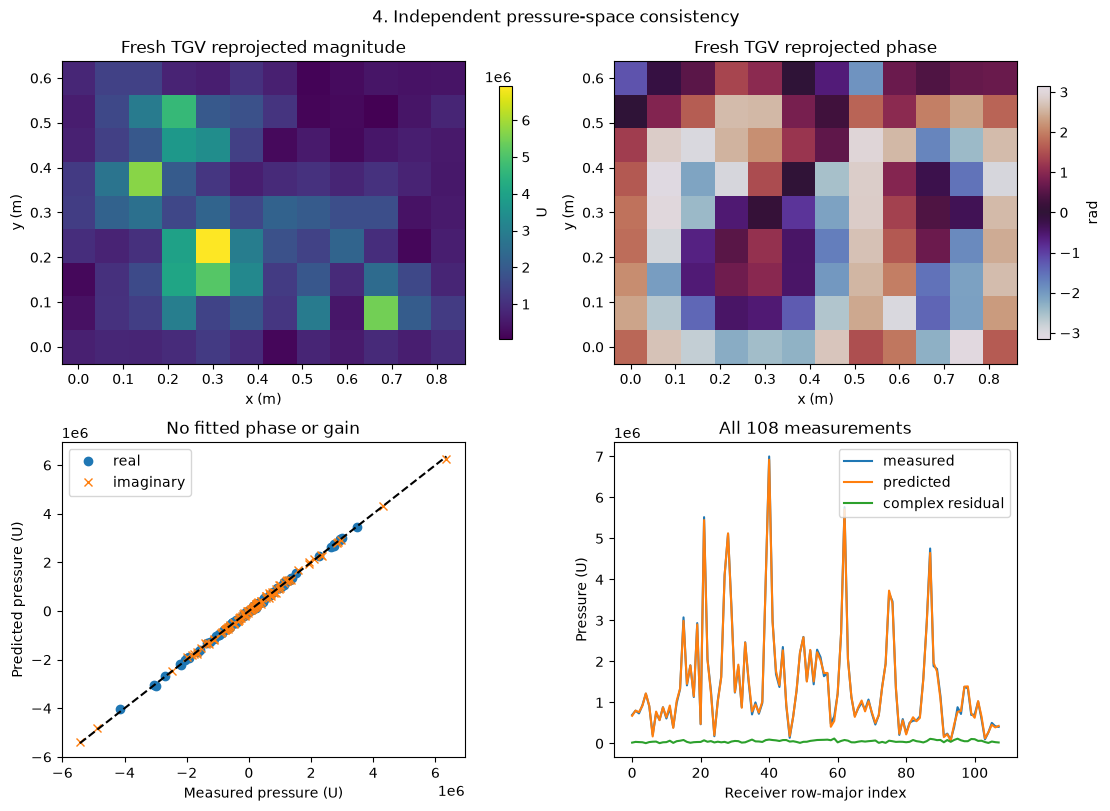

In [6]:
display(figures[3])
plt.close(figures[3])

### Figure 5

Actual fixed-iteration trajectory and independently recomputed regularization sensitivity; spatial image changes expose inverse nonuniqueness.


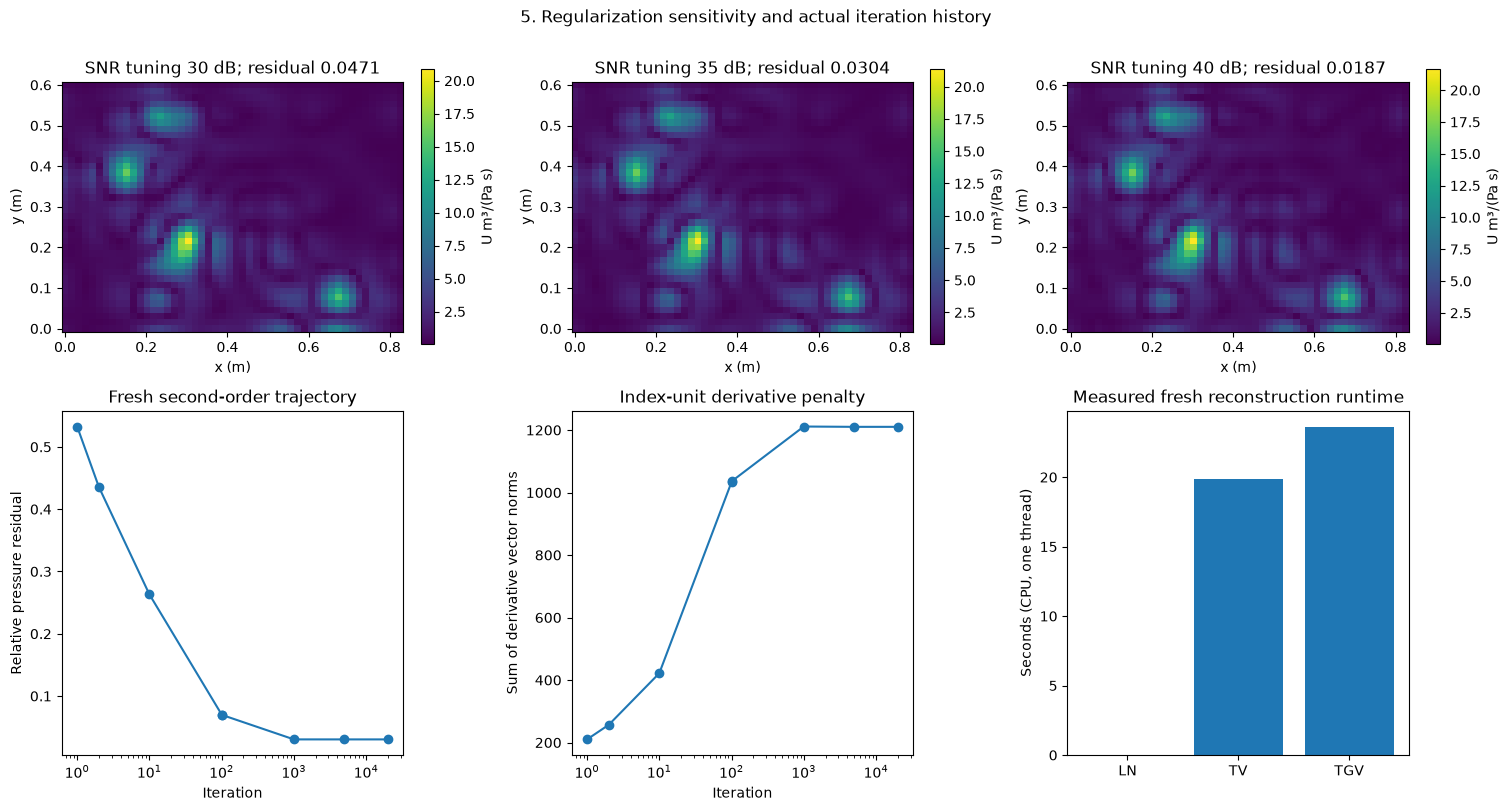

In [7]:
display(figures[4])
plt.close(figures[4])

## 6. Conclusion

### Conclusion and limits

The local classical inverses reproduce the separately captured original-code results on the exact real pressure. The standalone evaluator also tests complex pressure consistency. The supplied composed amplitude/phase convention fixes the numerical source scale, but does not provide an absolute acoustic calibration. The finite source plane, free-field model, sparse sampling and selected spatial prior limit physical identifiability. These maps are equivalent-source reconstructions; known loudspeaker outlines are not source-strength truth. Exported figure files and numeric_sources.npz contain the actual fresh calculations and clearly identified original captures.
